In [ ]:
from google.colab import files

uploaded = files.upload()

# MACHINE LEARNING MODEL
# Internet Usage Patterns Among Students

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Check whether dataset is loaded
try:
    df
except NameError:
    from google.colab import files
    uploaded = files.upload()
    filename = list(uploaded.keys())[0]
    df = pd.read_csv(filename)

# Clean column names
df.columns = (df.columns.str.replace('\n', ' ', regex=False)
              .str.strip().str.replace(r'\s+', ' ', regex=True))

# Define input features
features = [
    "How many hours do you spend on the internet per day?",
    "What is your main purpose for using the internet?",
    "Which platform do you use most frequently?",
    "How frequently do you use the internet for academic purposes?"
]

# Define target variable
target = "Does internet usage sometimes distract you from your studies?"

# Check required columns
missing = [col for col in features + [target]
           if col not in df.columns]

if missing:
    raise ValueError("Columns not found: " + str(missing))

# Remove rows with missing target values
data = df.dropna(subset=[target]).copy()

# Separate input and output
X = data[features].astype("object")
y = data[target].astype(str).str.strip()

# Remove classes with only one response
counts = y.value_counts()
valid_classes = counts[counts >= 2].index

data = data[y.isin(valid_classes)]
X = data[features].astype("object")
y = data[target].astype(str).str.strip()

if y.nunique() < 2:
    raise ValueError("Not enough target categories to train the model.")

# Preprocessing
preprocessor = ColumnTransformer([
    ("categorical",
     Pipeline([
         ("imputer", SimpleImputer(strategy="most_frequent")),
         ("encoder", OneHotEncoder(handle_unknown="ignore"))
     ]),
     features)
])

# Create Random Forest model
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train model
model.fit(X_train, y_train)

# Predict results
y_pred = model.predict(X_test)

# Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("MODEL TRAINED SUCCESSFULLY!")
print("\nModel: Random Forest Classifier")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

print("\nConfusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.xticks(range(len(model.classes_)), model.classes_,
           rotation=30)
plt.yticks(range(len(model.classes_)), model.classes_)

for i in range(len(cm)):
    for j in range(len(cm)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Number of rows and columns: (107, 16)


,Timestamp,Which device do you mainly used to access the internet,Age,How many hours do you spend on the internet per day?\n,When do you use the internet the most?\n\n\n\n,How frequently do you use the internet for academic purposes?,What is your main purpose for using the internet?,Which platform do you use most frequently?,Which online activity takes most of your internet time?,How often do you use the internet for learning new skills?,Do you think internet usage helps improve your academic performance?\nStrongly agree,Does internet usage sometimes distract you from your studies?,How often do you check your phone/internet without a specific purpose?,How would you rate your overall internet usage?,What do you think would help students maintain healthier internet usages?,Approximately how much of your daily internet usage is related to studies?
0,2026/08/16 11:48:19 am GMT+5:30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026/08/16 1:08:41 pm GMT+5:30,Smartphone,19-20,2-3hour,Evening,Occasionally,Social media,Other,Watching videos,Occasionally,Agree,"Yes, sometimes",Rarely,Moderate,Better time management,20–40%
2,2026/08/16 1:09:13 pm GMT+5:30,Smartphone,18-19,More than 3 hour,Night,Sometimes,Entertainment,Instagram,Messaging,Sometimes,Neutral,"Yes, frequently",Often,Very high,Screen-time reminders,Less than 20%
3,2026/08/16 1:12:17 pm GMT+5:30,Smartphone,20-21,More than 3 hour,Night,Rarely,Entertainment,Instagram,Social media,Rarely,Agree,"Yes, sometimes",Often,High,Limiting social media,Less than 20%
4,2026/08/16 1:13:04 pm GMT+5:30,Smartphone,18-19,More than 3 hour,Night,Sometimes,Social media,Instagram,Social media,Sometimes,Strongly agree,"Yes, frequently",Often,High,Study schedules,More than 80%


In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Column names:
['Timestamp', 'Which device do you mainly used to access the internet ', 'Age', 'How many hours do you spend on the internet per day?\n', 'When do you use the internet the most?\n\n\n\n', 'How frequently do you use the internet for academic purposes?', 'What is your main purpose for using the internet?', 'Which platform do you use most frequently?', 'Which online activity takes most of your internet time?', 'How often do you use the internet for learning new skills?', 'Do you think internet usage helps improve your academic performance?\nStrongly agree', 'Does internet usage sometimes distract you from your studies?', 'How often do you check your phone/internet without a specific purpose?', 'How would you rate your overall internet usage?', 'What do you think would help students maintain healthier internet usages?', 'Approximately how much of your daily internet usage is related to studies?']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 107 entr

In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
Timestamp                                                                               0
Which device do you mainly used to access the internet                                  2
Age                                                                                     2
How many hours do you spend on the internet per day?\n                                  2
When do you use the internet the most?\n\n\n\n                                          1
How frequently do you use the internet for academic purposes?                           1
What is your main purpose for using the internet?                                       1
Which platform do you use most frequently?                                              2
Which online activity takes most of your internet time?                                 1
How often do you use the internet for learning new skills?                              2
Do you think internet usage helps improve your academic performance?\

In [ ]:
df = df.dropna(
    subset=[col for col in df.columns if col != "Timestamp"],
    how="all"
)

print("Dataset shape after removing the blank response:")
print(df.shape)

Dataset shape after removing the blank response:
(106, 16)


In [ ]:
print("Statistical summary of numerical columns:")
df.describe()

Statistical summary of numerical columns:


,Timestamp,Which device do you mainly used to access the internet,Age,How many hours do you spend on the internet per day?\n,When do you use the internet the most?\n\n\n\n,How frequently do you use the internet for academic purposes?,What is your main purpose for using the internet?,Which platform do you use most frequently?,Which online activity takes most of your internet time?,How often do you use the internet for learning new skills?,Do you think internet usage helps improve your academic performance?\nStrongly agree,Does internet usage sometimes distract you from your studies?,How often do you check your phone/internet without a specific purpose?,How would you rate your overall internet usage?,What do you think would help students maintain healthier internet usages?,Approximately how much of your daily internet usage is related to studies?
count,106,105,105,105,106,106,106,105,106,105,104,105,105,105,103,105
unique,106,4,4,4,4,5,7,5,7,4,5,4,5,5,6,5
top,2026/08/16 1:08:41 pm GMT+5:30,Smartphone,19-20,More than 3 hour,Evening,Sometimes,Social media,Instagram,Social media,Sometimes,Neutral,"Yes, sometimes",Often,Moderate,Better time management,20–40%
freq,1,92,52,56,53,42,44,64,57,57,36,71,51,59,39,37


In [ ]:
print("Descriptive summary of the dataset:")

print(df.describe(include="all"))

Descriptive summary of the dataset:
                             Timestamp  \
count                              106   
unique                             106   
top     2026/08/16 1:08:41 pm GMT+5:30   
freq                                 1   

       Which device do you mainly used to access the internet     Age  \
count                                                 105         105   
unique                                                  4           4   
top                                            Smartphone       19-20   
freq                                                   92          52   

       How many hours do you spend on the internet per day?\n  \
count                                                 105       
unique                                                  4       
top                                      More than 3 hour       
freq                                                   56       

       When do you use the internet the most?\n\n\n\n  \
coun

How many hours do you spend on the internet per day?\n
More than 3 hour    56
2-3hour             26
1-2hour             22
Less than 1 hour     1
Name: count, dtype: int64


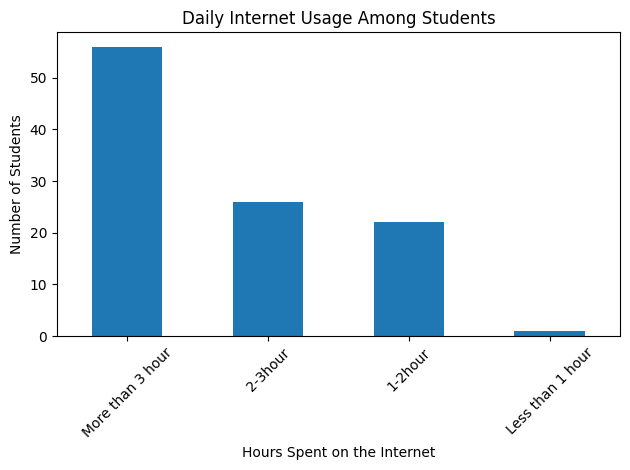

In [ ]:
hours = "How many hours do you spend on the internet per day?\n"

print(df[hours].value_counts())

df[hours].value_counts().plot(kind="bar")

plt.title("Daily Internet Usage Among Students")
plt.xlabel("Hours Spent on the Internet")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

What is your main purpose for using the internet?
Social media            44
Academic/studies        22
Entertainment           20
Other                    8
Gaming                   6
News/current affairs     3
Communication            3
Name: count, dtype: int64


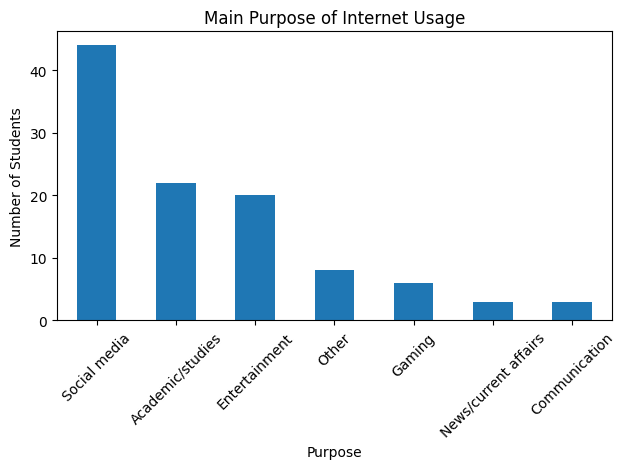

In [ ]:
purpose = "What is your main purpose for using the internet?"

print(df[purpose].value_counts())

df[purpose].value_counts().plot(kind="bar")

plt.title("Main Purpose of Internet Usage")
plt.xlabel("Purpose")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Which platform do you use most frequently?
Instagram    64
YouTube      16
Other        15
Google        7
WhatsApp      3
Name: count, dtype: int64


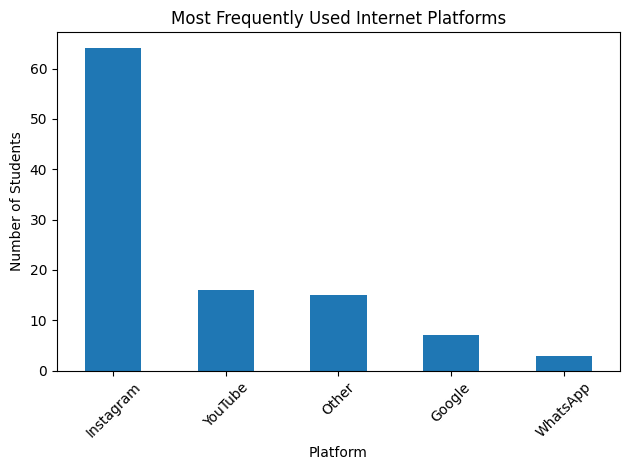

In [ ]:
platform = "Which platform do you use most frequently?"

print(df[platform].value_counts())

df[platform].value_counts().plot(kind="bar")

plt.title("Most Frequently Used Internet Platforms")
plt.xlabel("Platform")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

How frequently do you use the internet for academic purposes?
Sometimes       42
Often           33
Occasionally    23
Rarely           5
Never            3
Name: count, dtype: int64


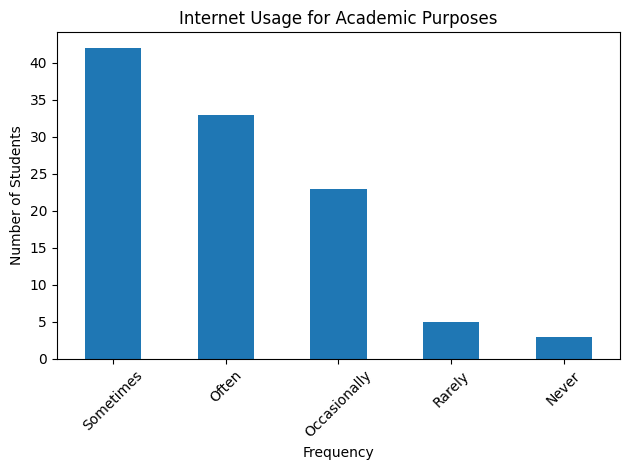

In [ ]:
academic = "How frequently do you use the internet for academic purposes?"

print(df[academic].value_counts())

df[academic].value_counts().plot(kind="bar")

plt.title("Internet Usage for Academic Purposes")
plt.xlabel("Frequency")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Does internet usage sometimes distract you from your studies?
Yes, sometimes     71
Yes, frequently    22
Rarely             10
Never               2
Name: count, dtype: int64


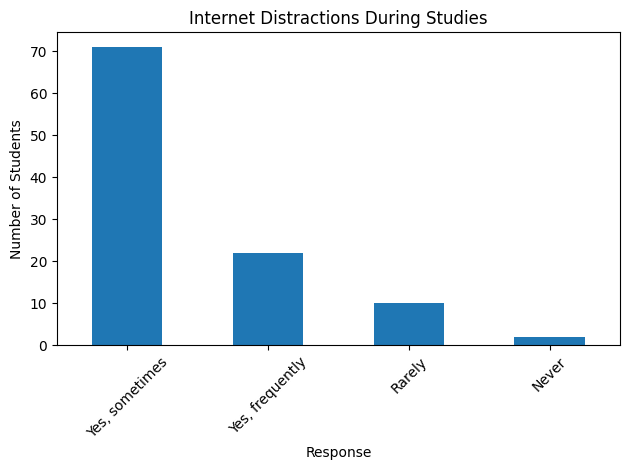

In [ ]:
distraction = "Does internet usage sometimes distract you from your studies?"

print(df[distraction].value_counts())

df[distraction].value_counts().plot(kind="bar")

plt.title("Internet Distractions During Studies")
plt.xlabel("Response")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Do you think internet usage helps improve your academic performance?\nStrongly agree
Neutral              36
Strongly agree       35
Agree                27
Disagree              4
Strongly disagree     2
Name: count, dtype: int64


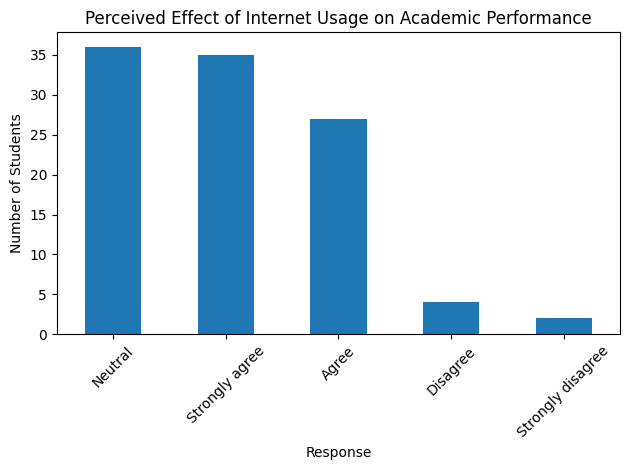

In [ ]:
performance = "Do you think internet usage helps improve your academic performance?\nStrongly agree"

print(df[performance].value_counts())

df[performance].value_counts().plot(kind="bar")

plt.title("Perceived Effect of Internet Usage on Academic Performance")
plt.xlabel("Response")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
questions = [
    "How many hours do you spend on the internet per day?\n",
    "What is your main purpose for using the internet?",
    "Which platform do you use most frequently?",
    "How frequently do you use the internet for academic purposes?",
    "Does internet usage sometimes distract you from your studies?"
]

for question in questions:
    print("\n", question)

    counts = df[question].value_counts()

    percentages = df[question].value_counts(normalize=True) * 100

    summary = pd.DataFrame({
        "Count": counts,
        "Percentage": percentages.round(2)
    })

    print(summary)


 How many hours do you spend on the internet per day?

                                                    Count  Percentage
How many hours do you spend on the internet per...                   
More than 3 hour                                       56       53.33
2-3hour                                                26       24.76
1-2hour                                                22       20.95
Less than 1 hour                                        1        0.95

 What is your main purpose for using the internet?
                                                   Count  Percentage
What is your main purpose for using the internet?                   
Social media                                          44       41.51
Academic/studies                                      22       20.75
Entertainment                                         20       18.87
Other                                                  8        7.55
Gaming                                                 6  

In [ ]:
hours = "How many hours do you spend on the internet per day?\n"

distraction = "Does internet usage sometimes distract you from your studies?"

print(pd.crosstab(df[hours], df[distraction]))

Does internet usage sometimes distract you from your studies?  Never  Rarely  \
How many hours do you spend on the internet per...                             
1-2hour                                                            2       3   
2-3hour                                                            0       3   
Less than 1 hour                                                   0       0   
More than 3 hour                                                   0       4   

Does internet usage sometimes distract you from your studies?  Yes, frequently  \
How many hours do you spend on the internet per...                               
1-2hour                                                                      2   
2-3hour                                                                      1   
Less than 1 hour                                                             0   
More than 3 hour                                                            19   

Does internet usage someti